In [20]:
import numpy as np
import pandas as pd
from sklearn.model_selection import train_test_split, KFold, cross_val_score
from sklearn.dummy import DummyRegressor
from sklearn.linear_model import LinearRegression, Ridge, Lasso
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler, PolynomialFeatures
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
df = pd.read_csv("lab_ticket_resolution.csv")
print(df.shape)
print(df.dtypes)
print(df.describe(include="all"))
print(df.isna().sum())

(240, 6)
ticket_id                    str
complexity_score           int64
lines_changed              int64
team_experience_years    float64
reopened                   int64
resolution_hours         float64
dtype: object
       ticket_id  complexity_score  lines_changed  team_experience_years    reopened  resolution_hours
count        240        240.000000     240.000000             240.000000  240.000000        240.000000
unique       240               NaN            NaN                    NaN         NaN               NaN
top        T0001               NaN            NaN                    NaN         NaN               NaN
freq           1               NaN            NaN                    NaN         NaN               NaN
mean         NaN          5.491667      54.820833               6.105417    0.233333         19.361125
std          NaN          2.979697      26.145017               3.391426    0.423836         10.035058
min          NaN          1.000000       1.000000         

Question 1


In [21]:
print("Shape:", df.shape)        
print("Data types:", df.dtypes)
print("Descriptive statistics:", df.describe(include="all").T)
print("Missing values:", df.isna().sum()) 
print("First five rows:", df.head())
print("Correlation matrix:", df.drop(columns="ticket_id").corr().round(3))

Shape: (240, 6)
Data types: ticket_id                    str
complexity_score           int64
lines_changed              int64
team_experience_years    float64
reopened                   int64
resolution_hours         float64
dtype: object
Descriptive statistics:                        count unique    top freq       mean        std  min     25%    50%      75%    max
ticket_id                240    240  T0001    1        NaN        NaN  NaN     NaN    NaN      NaN    NaN
complexity_score       240.0    NaN    NaN  NaN   5.491667   2.979697  1.0     3.0    5.5      8.0   10.0
lines_changed          240.0    NaN    NaN  NaN  54.820833  26.145017  1.0    33.0   54.0     74.0  113.0
team_experience_years  240.0    NaN    NaN  NaN   6.105417   3.391426  0.5     3.3    5.8      9.2   12.0
reopened               240.0    NaN    NaN  NaN   0.233333   0.423836  0.0     0.0    0.0      0.0    1.0
resolution_hours       240.0    NaN    NaN  NaN  19.361125  10.035058  0.5  11.015  19.61  27.1225  

Question 2

The target is resolution_hours. The features are complexity_score and team_experience_years, because both are known when a ticket is opened. I left out ticket_id (just a label), lines_changed (only known after the fix is written) and reopened (only known after the ticket is closed). Including those two would be data leakage.

In [22]:
target = "resolution_hours"
features = ["complexity_score", "team_experience_years"]
X = df[features]
y = df[target]
print(X)
print(y)

     complexity_score  team_experience_years
0                   6                    5.6
1                   9                   11.5
2                   6                    3.3
3                   5                    9.6
4                   3                    6.4
..                ...                    ...
235                10                    8.3
236                 7                    3.1
237                 3                    3.7
238                 3                    5.9
239                 4                    1.9

[240 rows x 2 columns]
0      24.77
1      33.43
2      17.82
3      19.54
4      11.04
       ...  
235    35.77
236    23.79
237    17.82
238    17.87
239    13.53
Name: resolution_hours, Length: 240, dtype: float64


Question 3

I split the data 80/20 with random_state=42, giving 192 training rows and 48 test rows. The test set is set aside and used only once at the end. For choosing models and settings I used 5-fold cross-validation inside the training set: train on 4 parts, check on the 5th, and repeat 5 times

In [23]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)
cv = KFold(n_splits=5, shuffle=True, random_state=42)

print("Train:", X_train.shape, " Test:", X_test.shape)

Train: (192, 2)  Test: (48, 2)


In [24]:
def cv_scores(model, Xtr, ytr):
    mae = -cross_val_score(model, Xtr, ytr, cv=cv, scoring="neg_mean_absolute_error")
    rmse = -cross_val_score(model, Xtr, ytr, cv=cv, scoring="neg_root_mean_squared_error")
    r2 = cross_val_score(model, Xtr, ytr, cv=cv, scoring="r2")
    return dict(cv_MAE=mae.mean(), cv_RMSE=rmse.mean(), cv_RMSE_sd=rmse.std(), cv_R2=r2.mean())
 
def fit_and_test(model, Xtr, ytr, Xte, yte):
    model.fit(Xtr, ytr)
    p = model.predict(Xte)
    out = dict(test_MAE=mean_absolute_error(yte, p),
               test_RMSE=np.sqrt(mean_squared_error(yte, p)),
               test_R2=r2_score(yte, p))
    ptr = model.predict(Xtr)
    out.update(train_RMSE=np.sqrt(mean_squared_error(ytr, ptr)), train_R2=r2_score(ytr, ptr))
    return out, p
 
models, results, preds = {}, {}, {}
 
def evaluate(name, model):
    models[name] = model
    row = cv_scores(model, X_train, y_train)
    t, p = fit_and_test(model, X_train, y_train, X_test, y_test)
    row.update(t)
    results[name] = row
    preds[name] = p
    return row

Question 4


In [25]:
b = evaluate("Dummy (mean)", DummyRegressor(strategy="mean"))
print({k: round(v, 3) for k, v in b.items() if k.startswith("test")})

{'test_MAE': 9.114, 'test_RMSE': np.float64(10.598), 'test_R2': -0.021}


Question 5

In [26]:
l = evaluate("Linear", make_pipeline(StandardScaler(), LinearRegression()))
print({k: round(float(v), 3) for k, v in l.items() if k.startswith("test")})

{'test_MAE': 2.906, 'test_RMSE': 3.572, 'test_R2': 0.884}


Question 6

In [27]:
for d in (2, 3):
    pipe = make_pipeline(PolynomialFeatures(d, include_bias=False), StandardScaler(), LinearRegression())
    r = evaluate(f"Poly deg{d}", pipe)
    print(f"degree {d}: CV RMSE = {r['cv_RMSE']:.3f} (+/- {r['cv_RMSE_sd']:.3f}), "
          f"CV MAE = {r['cv_MAE']:.3f}, CV R2 = {r['cv_R2']:.3f}")

degree 2: CV RMSE = 3.832 (+/- 0.461), CV MAE = 3.131, CV R2 = 0.844
degree 3: CV RMSE = 3.877 (+/- 0.314), CV MAE = 3.162, CV R2 = 0.841


Question 7

In [28]:
alphas = np.logspace(-3, 2, 30)         

lasso_alphas = np.logspace(-3, 1, 30)      
def pick_alpha(make_model, grid):
    rmses = []
    for a in grid:
        s = cross_val_score(make_model(a), X_train, y_train, cv=cv,
                            scoring="neg_root_mean_squared_error")
        rmses.append(-s.mean())
    rmses = np.array(rmses)
    return grid[rmses.argmin()], rmses
 
ridge_alpha, ridge_curve = pick_alpha(lambda a: make_pipeline(StandardScaler(), Ridge(alpha=a)), alphas)
lasso_alpha, lasso_curve = pick_alpha(
    lambda a: make_pipeline(StandardScaler(), Lasso(alpha=a, max_iter=100000)), lasso_alphas)
print(f"Ridge selected alpha = {ridge_alpha:.4f}") 
print(f"Lasso selected alpha = {lasso_alpha:.4f}")    
evaluate("Ridge (linear feats)", make_pipeline(StandardScaler(), Ridge(alpha=ridge_alpha)))
evaluate("Lasso (linear feats)", make_pipeline(StandardScaler(), Lasso(alpha=lasso_alpha, max_iter=100000)))
 
ridge3_alpha, _ = pick_alpha(
    lambda a: make_pipeline(PolynomialFeatures(3, include_bias=False), StandardScaler(), Ridge(alpha=a)), alphas)
lasso3_alpha, _ = pick_alpha(
    lambda a: make_pipeline(PolynomialFeatures(3, include_bias=False), StandardScaler(),
                            Lasso(alpha=a, max_iter=200000)), lasso_alphas)
print(f"Ridge on degree-3 features: selected alpha = {ridge3_alpha:.4f}")   
print(f"Lasso on degree-3 features: selected alpha = {lasso3_alpha:.4f}")   
evaluate("Ridge (poly deg3)", make_pipeline(PolynomialFeatures(3, include_bias=False), StandardScaler(),
                                            Ridge(alpha=ridge3_alpha)))
evaluate("Lasso (poly deg3)", make_pipeline(PolynomialFeatures(3, include_bias=False), StandardScaler(),
                                            Lasso(alpha=lasso3_alpha, max_iter=200000)))
 
res = pd.DataFrame(results).T
res.index.name = "model"
pd.set_option("display.width", 200)
pd.set_option("display.max_columns", 20)
print("\nResults (CV on training set; test evaluated once)")
print(res.astype(float).round(3))
res.astype(float).round(4).to_csv("results_table.csv")

Ridge selected alpha = 0.5736
Lasso selected alpha = 0.0010
Ridge on degree-3 features: selected alpha = 1.8874
Lasso on degree-3 features: selected alpha = 0.0329

Results (CV on training set; test evaluated once)
                      cv_MAE  cv_RMSE  cv_RMSE_sd  cv_R2  test_MAE  test_RMSE  test_R2  train_RMSE  train_R2
model                                                                                                       
Dummy (mean)           8.448    9.884       0.754 -0.023     9.114     10.598   -0.021       9.869     0.000
Linear                 3.168    3.909       0.411  0.838     2.906      3.572    0.884       3.869     0.846
Poly deg2              3.131    3.832       0.461  0.844     3.020      3.741    0.873       3.770     0.854
Poly deg3              3.162    3.877       0.314  0.841     3.140      3.949    0.858       3.702     0.859
Ridge (linear feats)   3.168    3.909       0.414  0.838     2.906      3.571    0.884       3.869     0.846
Lasso (linear feats)  

Lasso is useful when a model is too complex and needs to be simplified. In the first case, the model only has two features and 192 training examples. Ordinary least squares already works well, and both features are useful. So Lasso doesn’t have anything helpful to remove. Its penalty could make the model less accurate.

The degree 3 model is more complex. It turns the original two features into nine terms, some of which are closely related. This can make the model overfit the training data. Ridge helps by shrinking the coefficients. Lasso also shrinks them, and it sets four of the nine coefficients to zero, which simplifies the model

Question 8

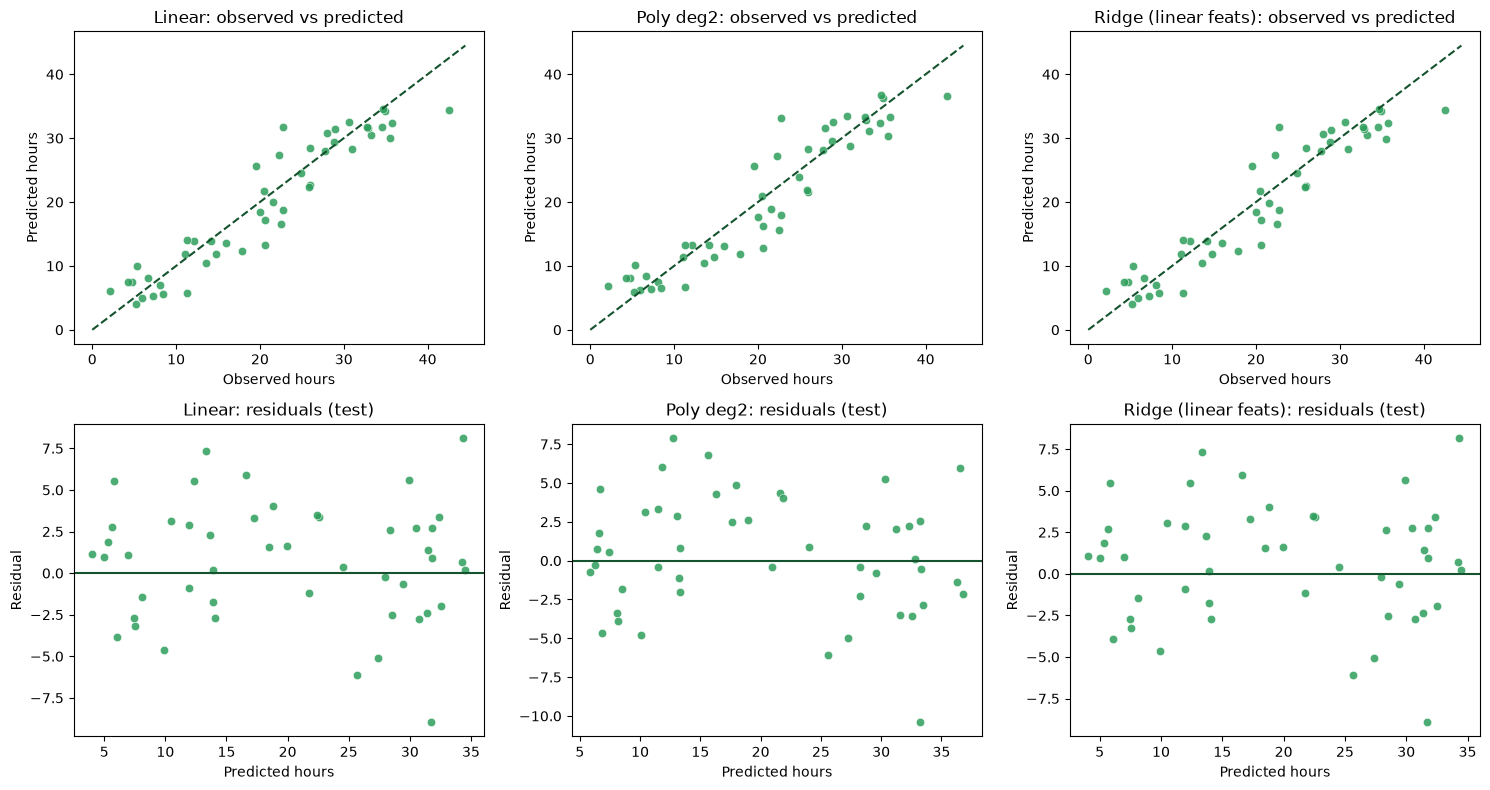

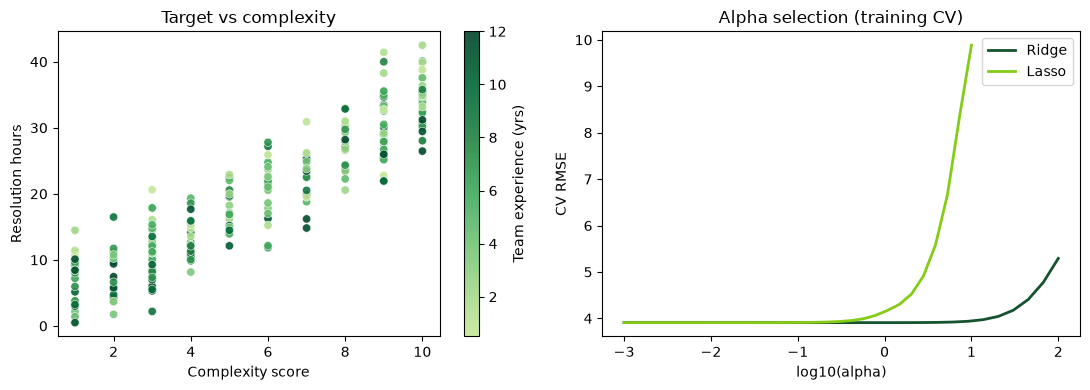

Residual SD, lower half of target / upper half (test): 3.33 3.65
Largest |residual| in training data: 10.57
Mean training residual by complexity score:
{1: 1.87, 2: 0.13, 3: -1.14, 4: -1.01, 5: -0.15, 6: -0.52, 7: -0.91, 8: 0.55, 9: 0.23, 10: 0.96}


In [29]:
import matplotlib.pyplot as plt     
MAIN, DARK, LIGHT = "#2e9e5b", "#14532d", "#84cc16"     
chosen = ["Linear", "Poly deg2", "Ridge (linear feats)"]
fig, axes = plt.subplots(2, 3, figsize=(15, 8))
for j, n in enumerate(chosen):
    p = preds[n]
    ax = axes[0, j]
    ax.scatter(y_test, p, alpha=.85, color=MAIN, edgecolors="white", linewidths=.4)
    lim = [0, max(y_test.max(), p.max()) + 2]
    ax.plot(lim, lim, "--", color=DARK, lw=1.5)
    ax.set(title=f"{n}: observed vs predicted", xlabel="Observed hours", ylabel="Predicted hours")
    ax = axes[1, j]
    ax.scatter(p, y_test - p, alpha=.85, color=MAIN, edgecolors="white", linewidths=.4)
    ax.axhline(0, color=DARK, lw=1.5)
    ax.set(title=f"{n}: residuals (test)", xlabel="Predicted hours", ylabel="Residual")
plt.tight_layout()
plt.show()

from matplotlib.colors import ListedColormap     
green_cmap = ListedColormap(plt.cm.YlGn(np.linspace(0.3, 1.0, 256)))
fig, ax = plt.subplots(1, 2, figsize=(11, 4))
sc = ax[0].scatter(df.complexity_score, df.resolution_hours, c=df.team_experience_years,
                   cmap=green_cmap, alpha=.9, edgecolors="white", linewidths=.4)
plt.colorbar(sc, ax=ax[0], label="Team experience (yrs)")
ax[0].set(xlabel="Complexity score", ylabel="Resolution hours", title="Target vs complexity")
ax[1].plot(np.log10(alphas), ridge_curve, label="Ridge", color=DARK, lw=2)
ax[1].plot(np.log10(lasso_alphas), lasso_curve, label="Lasso", color=LIGHT, lw=2)
ax[1].set(xlabel="log10(alpha)", ylabel="CV RMSE", title="Alpha selection (training CV)")
ax[1].legend()
plt.tight_layout()
plt.show()
 
p = preds["Linear"]
r = y_test.values - p
lo = y_test.values < np.median(y_test)
print("Residual SD, lower half of target / upper half (test):", r[lo].std().round(2), r[~lo].std().round(2))
rt = y_train.values - models["Linear"].predict(X_train)
print("Largest |residual| in training data:", np.abs(rt).max().round(2))
print("Mean training residual by complexity score:")
print(pd.Series(rt).groupby(X_train["complexity_score"].values).mean().round(2).to_dict())

Question 9

I’d choose linear regression because it predicts ticket resolution time more accurately than the mean baseline. Its average test error is about 3.6 hours, compared with 10.6 hours for the baseline. The model also suggests that more complex tickets take longer to resolve, while more experienced teams resolve them faster. Before using it, I’d test it on newer tickets and confirm that its input information is available when a ticket is opened.

Question 10

The mean baseline predicts the same average resolution time 19.4 hours for every ticket. It gives us a simple point of comparison. If a more advanced model can’t make better predictions than that, using its features and added complexity isn’t helping.

Question 11

MAE and RMSE both measure prediction errors in hours. MAE averages the error sizes. RMSE gives larger errors more influence, so a few large mistakes can affect it more.
On the test set, linear regression, Ridge, and Lasso tied for the lowest MAE at 2.906 hours. Ridge had the lowest RMSE at 3.571 hours, compared with 3.572 for the other two. That difference is tiny, so I’d consider them effectively tied. The models with the lowest MAE and RMSE can differ because RMSE weighs large errors more heavily. Cross-validation also showed small differences, so I’d favor the simpler model when performance is similar.

Question 12

Polynomial features let the model capture curved relationships, but they didn’t improve performance much here. Degree 2 had slightly lower cross-validation error than the linear model, but the difference was small. Degree 3 performed worse.
There’s also evidence of overfitting: as the models became more complex, training error fell while test error rose. The degree 3 model’s test R² was 0.858, compared with 0.884 for linear regression. This suggests it fit the training tickets better but predicted new tickets less well.

Question 13

Regularization discourages large coefficients. With just two features, Ridge and Lasso barely changed the model or its test error. With the more complex degree 3 model, they reduced coefficient sizes, and Lasso set some coefficients to zero. This improved the degree 3 model’s test performance.


Question 14

Ridge and Lasso penalize coefficient sizes, so I scaled the features to put them on comparable measurement scales. Otherwise, the penalty could affect a feature more just because of its units. Scaling in the pipeline also ensures it’s calculated separately using each training fold during cross-validation.

Question 15

I left out lines_changed and reopened because those values may only be known after work is done or a ticket is closed. Including them made the model’s scores look better, but it would give an unrealistic picture of how well the model could predict resolution time when a ticket is opened.

Question 16

A random split may not be suitable if tickets were collected over several years, because the model could learn from newer tickets and then be tested on older ones. To better represent future use, I’d train on earlier tickets and test on later ones. I’d also check how well the model works on teams kept separate from the training data.

Question 17

Before deployment, I’d test the model on newer tickets, confirm its input features are available when predictions are made, and investigate its largest errors. I’d check whether it can predict impossible values, such as negative resolution time, and whether its performance stays stable across different data splits. I’d also compare its predictions with human estimates and monitor its performance over time.